
# Laboratorium 2: Baseline i kasyfikator



W poprzednim laboratorium zaczęliśmy od danych. Dzisiaj budujemy pierwszy pełny eksperyment z zakresu uczenia maszynowego.

Nasza ścieżka:

`dane → baseline → TF-IDF → klasyfikator → metryki → analiza błędów → decyzja`

Interesuje nas:

- jakość,
- stabilność,
- szybkość,
- koszt,
- interpretowalność,
- rodzaj popełnianych błędów.

> **Pytanie badawcze na dziś:** jak mocny jest prosty model tekstowy i kiedy naprawdę potrzebujemy transformera albo LLM-a?

## Po tych zajęciach student potrafi:

- zbudować klasyfikator;
- reprezentować tekst przez TF-IDF;
- wytrenować `LogisticRegression` i `LinearSVC`;
- poprawnie używać `accuracy`, `macro-F1`, `precision`, `recall`;
- analizować confusion matrix;
- porównywać modele eksperymentalnie;
- sprawdzać wpływ długości tekstu na wynik;
- analizować najbardziej pewne błędne predykcje;
- interpretować cechy modelu liniowego;
- przeprowadzić mini „NLP Arena”.

### Zasada na dziś

> **Nowy, większy model musi pokonać mocny baseline. Inaczej nie wiemy, czy naprawdę coś zyskaliśmy.**


## Dane

Laboratorium zakłada, że po wykonaniu laboratorium 1 mają Państwo:

```text
artifacts/polemo2_clean.parquet
artifacts/splits.json
```

Jeśli plików nie ma, proszę wrócić do Lab 1. Nie pobieramy danych ponownie, bo wtedy tracimy czyszczenie, manifest i sumy kontrolne.
Pracujemy na oryginalnym podziale zbioru.


## Setup

In [59]:

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay, confusion_matrix,
)
import joblib

RANDOM_STATE = 42
ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 50)


In [60]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

In [61]:
import hashlib

DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
MANIFEST_PATH = ARTIFACTS / "splits.json"

# TODO: wczytać dane z Lab 1 i utworzyć train_df, val_df, test_df.
# Proszę sprawdzić:
#  - czy suma SHA-256 pliku parquet zgadza się z wartością w splits.json,
#  - czy etykiety to dokładnie: plus / minus / zero / amb,
#  - czy rozmiary splitów zgadzają się z split_sizes_clean z manifestu.
# Jeśli pliku nie ma, proszę wrócić do Lab 1 (nie pobieramy danych "po cichu").

# MIEJSCE NA KOD


manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

def sha256_file(path, chunk_size=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

sha = sha256_file(DATA_PATH)
assert sha == manifest["parquet_sha256"], f"SHA-256 mismatch: {sha}"

df = pd.read_parquet(DATA_PATH)

EXPECTED_LABELS = {"plus", "minus", "zero", "amb"}
labels =  set(df["target"].unique())
assert labels == EXPECTED_LABELS, f"Unexpected labels: {labels - EXPECTED_LABELS}"

train_df =  df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

sizes = {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
assert manifest["split_sizes_clean"] == sizes, f"Split sizes mismatch: {sizes}"



print("SHA-256 OK:", sha[:16], "...")
print("Sizes:", sizes)
print(train_df["target"].value_counts(normalize=True).round(3))

SHA-256 OK: fa27e9ec45ded6b1 ...
Sizes: {'train': 5782, 'validation': 723, 'test': 722}
target
minus    0.379
plus     0.271
amb      0.181
zero     0.168
Name: proportion, dtype: float64



# Zadanie 1: Zamrożenie protokołu eksperymentalnego

Zanim wytrenują Państwo model, proszę zdefiniować zbiory:

- **train**: do uczenia,
- **validation**: do wyboru wariantu,
- **test**: testowany dopiero na końcu,
- główną metrykę,
- metryki pomocnicze.

### Dla tego laboratorium

Główna metryka: `macro-F1`

Dlaczego nie samo accuracy?

Bo `macro-F1` liczy F1 osobno dla każdej klasy, a potem uśrednia je z równą wagą. Słaba jakość na małej klasie nie „schowa się” za dużą klasą.

### Hipoteza badawcza

Przed uruchomieniem modeli proszę wpisać hipotezę:

> Który model wygra: prosty baseline, Logistic Regression czy Linear SVM? Dlaczego?

Wydaje mi sie, ze wygra **Logistic Regression**. Jest to model liniowy, który jest prosty do interpretacji i szybki do uczenia. W tym przypadku, gdzie mamy mały zbiór danych i wiele cech, może być lepszy niż Linear SVM, który jest bardziej skomplikowany i może być trudniejszy do interpretacji.


In [62]:
# MIEJSCE NA KOD

X_train = train_df["text"]
y_train = train_df["target"]

X_val = val_df["text"]
y_val = val_df["target"]

X_test = test_df["text"]
y_test = test_df["target"]



# Zadanie 2: Baseline większościowy

Najprostszy model klasyfikujący działa wg zasady: zawsze przewiduj najczęstszą klasę. Jeśli skomplikowany model ledwie pokonuje `DummyClassifier`, mamy problem.


In [63]:
# TODO: porównać dwa warianty DummyClassifier:
#   strategy="most_frequent"
#   strategy="stratified", random_state=RANDOM_STATE
# Raportować accuracy i macro-F1 na validation.

dummies = {
    "most_frequent": DummyClassifier(strategy="most_frequent"),
    "stratified":    DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

rows = []
for name, clf in dummies.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    rows.append({
        "model": f"Dummy({name})",
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": macro_f1(y_val, pred),
    })

dummy_results = pd.DataFrame(rows).set_index("model").round(3)
dummy_results

,accuracy,macro_f1
model,,
Dummy(most_frequent),0.375,0.136
Dummy(stratified),0.268,0.231


Proszę odpowiedzieć na pytania:

1. Dlaczego accuracy majority baseline może wyglądać „nieźle”?
2. Dlaczego macro-F1 jest znacznie niższe?
3. Jaki wynik musi osiągnąć kolejny model, żeby w ogóle mówić o istotnym postąpieniu w analizie danych?


1. Klasa minus stanowi ok. 37,5% zbioru walidacyjnego. Model, który zawsze przewiduje minus, trafia więc w 37,5% przypadków. Nie korzysta przy tym z treści tekstu, tylko z niezbalansowania klas. Wynik jest wyraźnie wyższy niż przy losowym zgadywaniu spośród 4 klas (25%), ale nie oznacza żadnej zdolności rozróżniania sentymentu.

2. Dlaczego macro-F1 jest znacznie niższe? Macro-F1 liczy F1 osobno dla każdej klasy i uśrednia wyniki z równą wagą. Majority baseline nigdy nie przewiduje plus, zero ani amb, więc F1 dla tych klas wynosi 0. Niezerowe F1 ma tylko klasa minus (ok. 0,545), a średnia z czterech klas daje ok. 0,136. Macro-F1 ujawnia więc to, co accuracy ukrywa: model całkowicie ignoruje trzy z czterech klas. Baseline stratified losuje etykiety proporcjonalnie do częstości klas. Ma przez to niższe accuracy (0,268), ale wyższe macro-F1 (0,231), bo czasem trafia także w mniejsze klasy.

3. Główną metryką jest macro-F1, więc punktem odniesienia jest najlepszy baseline pod tym względem, czyli stratified: 0,231 (95% CI z bootstrapu: 0,204–0,264). O istotnym postępie można mówić dopiero wtedy, gdy przedział ufności nowego modelu nie zachodzi na przedział baseline'u, czyli jego dolna granica przekracza ok. 0,26. Różnica rzędu kilku setnych mieści się w losowej zmienności baseline'u.


# TF-IDF: zamieniamy tekst na dane liczbowe

Zamieńmy tekst na reprezentację liczbową. Najpierw budujemy macierz:

`dokument × cecha`

W klasycznym TF-IDF cechą może być słowo albo n-gram. Co jest bardziej znaczące dla tekstu?

Intuicja:

- słowo częste w konkretnym dokumencie jest ważne,
- słowo częste wszędzie wnosi mniej informacji o tekście i jego znaczeniu.

### Pierwszy wariant

- word n-grams: `(1, 2)`,
- `min_df=2`,
- maks. `50_000` cech,
- `sublinear_tf=True`.


In [64]:
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)

# Zadanie 3: Reprezentacja rzadka (Sparse Representation)

Proszę obliczyć liczbę wszystkich elementów macierzy, liczbę wartości niezerowych oraz gęstość macierzy. Następnie proszę wyjaśnić, dlaczego rzadka reprezentacja wektorowa dobrze sprawdza się w przypadku TF-IDF.


In [65]:
# TODO

X_train_tfidf = word_tfidf.fit_transform(X_train)
X_val_tfidf = word_tfidf.transform(X_val)

total_cells = X_train_tfidf.shape[0] * X_train_tfidf.shape[1]
nonzero = X_train_tfidf.nnz
density = nonzero / total_cells

print(f'Shape: {X_train_tfidf.shape}')
print(f'Total cells: {total_cells:,}')
print(f'Nonzero cells: {nonzero:,}')
print(f'Density: {density:.2%}')

Shape: (5782, 50000)
Total cells: 289,100,000
Nonzero cells: 648,304
Density: 0.22%


Macierz TF-IDF ma wymiary 5782 × 50000 (289,100,000 elementów), ale tylko 648,304 z nich jest niezerowych, co daje gęstość ok. 0.22%. Każda recenzja zawiera zaledwie ułamek słów i bigramów ze słownika, więc prawie wszystkie wartości to zera. Format rzadki przechowuje tylko niezerowe wartości, dzięki czemu oszczędza pamięć i przyspiesza obliczenia, a modele liniowe działają na nim bezpośrednio.


# Regresja logistyczna (Logistic Regression)

To będzie nasz pierwszy prawdziwy klasyfikator. Model liniowy uczy wag przypisanych do cech tekstowych.
Dla klasy sentymentu może nauczyć się np., że:

- pewne słowa i frazy zwiększają prawdopodobieństwo `plus`,
- inne zwiększają prawdopodobieństwo `minus`.


In [66]:
# TODO: Pipeline(word_tfidf + LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))


log_reg_pipe = Pipeline(
    steps=[
        ("tfidf", clone(word_tfidf)),
        ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
)

log_reg_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['amb','minus','plus','zero']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",50000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'



# Zadanie 4: Klasyfikacja

Proszę zaprezentować pełny `classification_report`.

### Proszę odpowiedzieć na pytania:

1. Która klasa ma najwyższy recall?
2. Która ma najniższy?
3. Dla której klasy precision i recall najbardziej się różnią?
4. Która klasa jest dla modelu najtrudniejsza i dlaczego?
5. Co te liczby sugerują o danych?

In [67]:
# TODO: classification_report

y_pred_log_reg = log_reg_pipe.predict(X_val)
print(classification_report(y_val, y_pred_log_reg))

              precision    recall  f1-score   support

         amb       0.61      0.40      0.48       116
       minus       0.78      0.95      0.86       271
        plus       0.89      0.82      0.86       209
        zero       0.99      0.97      0.98       127

    accuracy                           0.83       723
   macro avg       0.82      0.78      0.79       723
weighted avg       0.82      0.83      0.82       723



1. Najwyższy recall ma klasa zero (0,97).
2. Najniższy recall ma klasa amb (0,40). Model rozpoznaje mniej niż połowę recenzji ambiwalentnych.
3. Największa różnica między precision a recall występuje dla amb (0,61 vs 0,40, różnica 0,21). Model rzadko przewiduje tę klasę, a i tak często się przy tym myli.
4. Najtrudniejsza jest klasa amb, bo ma najniższe precision, recall i F1 (0,48), wyraźnie niższe niż pozostałe klasy (0,86–0,98).

5. Wyniki sugerują, że klasy w PolEmo2 różnią się stopniem jednoznaczności. Klasa zero (teksty neutralne, często niebędące opiniami) ma wyraźnie inne słownictwo, więc jest niemal idealnie rozpoznawana (F1 0,98). Klasy plus i minus też mają wyraźne sygnały językowe. Klasa amb łączy natomiast pozytywne i negatywne sformułowania w jednym tekście, więc z natury nakłada się na pozostałe klasy, a granica między „ambiwalentną” a „raczej negatywną” recenzją bywa subiektywna nawet dla anotatorów.


# Liniowe wekory nośne (Linear SVM)

Dla tekstu klasyczny Linear SVM jest bardzo mocnym baselinem - działa prosto i szybko, nie komplikuje nadmiernie agregowania informacji o tekście. Czy prosty model liniowy okaże się trudnym przeciwnikiem dla dużo większych modeli?


In [68]:
#TODO: LinearSVC()

linear_svc_pipe = Pipeline(
    steps =[
    ('tfidf', clone(word_tfidf)),
    ('linear_svc', LinearSVC())
    ]
)
linear_svc_pipe.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('linear_svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['amb','minus','plus','zero']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",50000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'


In [69]:
y_pred_svc = linear_svc_pipe.predict(X_val)
print(classification_report(y_val, y_pred_svc))

              precision    recall  f1-score   support

         amb       0.53      0.41      0.46       116
       minus       0.81      0.92      0.86       271
        plus       0.87      0.82      0.84       209
        zero       0.97      0.99      0.98       127

    accuracy                           0.82       723
   macro avg       0.80      0.79      0.79       723
weighted avg       0.81      0.82      0.81       723




# Zadanie 5: Pierwszy leaderboard

Proszę zbudować tabelę:

| model | accuracy | macro-F1 | macro_f1_ci95 | macro-precision | macro-recall | train_s | infer_ms/doc |
|---|---:|---:|---:|---:|---:|---:|---:|

Modele:

- prosty baseline,
- TF-IDF + Logistic Regression,
- TF-IDF + Linear SVM.

Proszę posortować po macro-F1. Przedział ufności liczymy funkcją bootstrap_ci. Czas treningu mierzymy dla całego Pipeline (łącznie z TF-IDF), a infer_ms/doc jako medianę z 3 powtórzeń predict na validation.

### Ważne

To jest leaderboard na zbiorze walidacyjnym. Do pełnego porównania jeszcze dotrzemy.

In [70]:
# TODO: DataFrame leaderboard_valid


models = {
    "Dummy stratified": dummies["stratified"],
    "Logistic Regression": log_reg_pipe,
    "Linear SVM": linear_svc_pipe,
}
leaderboard_valid =  []

for model_name, model in models.items():
    s_time = time.perf_counter()
    model.fit(X_train, y_train)
    e_time = time.perf_counter()
    y_pred = model.predict(X_val)

    times = []
    for _ in range(3):
        t_1 = time.perf_counter()
        model.predict(X_val)
        t_2 = time.perf_counter()
        times.append(t_2 - t_1)

    row = {
        "model": model_name,
        "accuracy": accuracy_score(y_val, y_pred),
        "macro-F1": macro_f1(y_val, y_pred),
        "macro_f1_ci95": bootstrap_ci(y_val, y_pred, metric=macro_f1),
        "macro-precision": precision_score(y_val, y_pred,average="macro"),
        "macro-recall": recall_score(y_val, y_pred,average="macro"),
        "train_s": e_time - s_time,
        "infer_ms/doc": np.median(times) / len(X_val) * 1000
    }
    leaderboard_valid.append(row)

leaderboard_valid_df = pd.DataFrame(leaderboard_valid).sort_values(by="macro-F1", ascending=False).reset_index(drop=True)

leaderboard_valid_df

,model,accuracy,macro-F1,macro_f1_ci95,macro-precision,macro-recall,train_s,infer_ms/doc
0,Logistic Regression,0.827109,0.792552,"(0.7925522513838653, 0.7640712044284593, 0.8225527813181953)",0.816795,0.784090,2.236875,0.078701
1,Linear SVM,0.821577,0.787961,"(0.7879605573696461, 0.758393756758181, 0.8166342233841294)",0.795719,0.785730,1.618065,0.081685
2,Dummy stratified,0.268326,0.230972,"(0.23097218227899424, 0.20355727728012016, 0.2636969746548121)",0.231462,0.231387,0.002649,0.000380


**Weryfikacja hipotezy:** hipoteza się potwierdziła: Logistic Regression wygrała z macro-F1 0.793 wobec 0.788 dla Linear SVM (oba modele na tej samej reprezentacji TF-IDF). Różnica 0.005 jest jednak dużo mniejsza niż szerokość przedziałów ufności (0.764–0.823 vs 0.758–0.817), więc w praktyce oba modele są równorzędne. Oba bardzo wyraźnie pokonują baseline stratified (0.231, CI 0.204–0.264), a ich czasy treningu i inferencji są porównywalne.


# Confusion Matrix. Jak model się myli?

Jedna liczba nie mówi nam, co dzieje się w modelu.

Macierz pomyłek odpowiada m.in. na pytania:

- czy `amb` jest mylone z `plus`?
- czy `zero` wpada w `minus`?
- czy błędy są symetryczne?


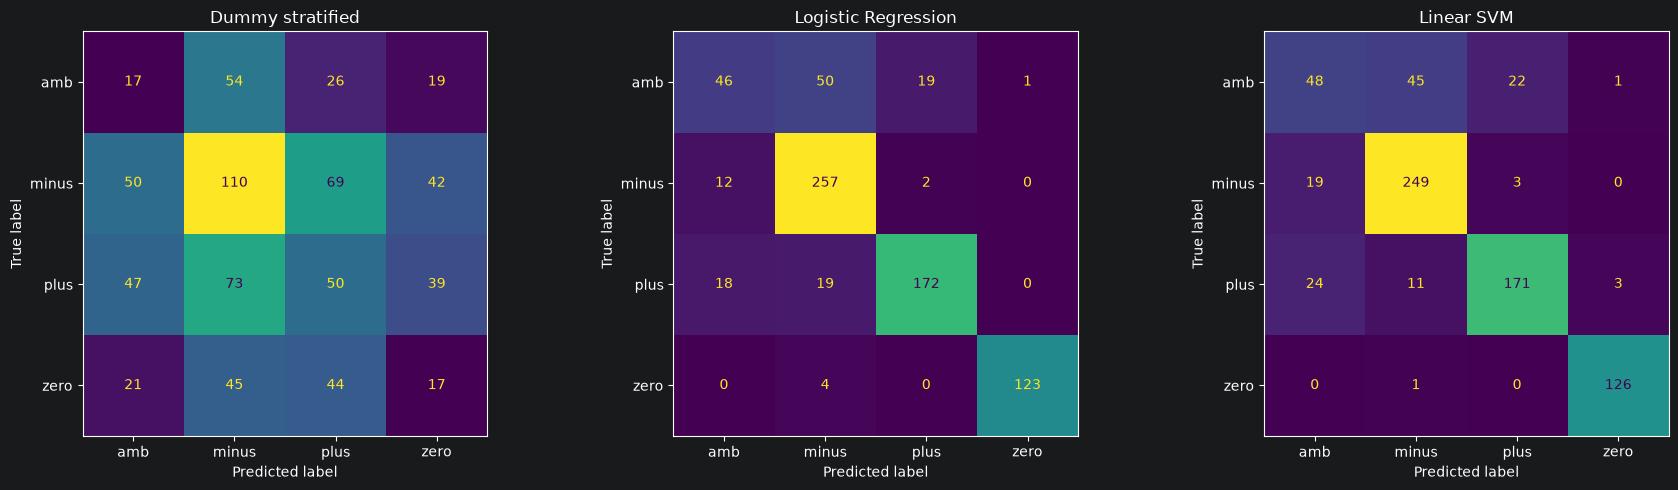

In [71]:
#TODO: ConfusionMatrix

labels =  sorted(y_val.unique())

fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_val)
    cm = confusion_matrix(y_val, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [72]:
X_val[(y_val == "amb") & (y_pred_svc == "minus")].head()

26    chodziła m do niego na wizyty - dodatkowe USG w ciąży , był też pierwszym ginekologiem do którego poszła m , spodziewając się , że jestem w ciąży . Była m zadowolona , choć moż...
29    Pani doktor miła lecz po przyjściu z pewnym problemem stwierdziła , że to nic takiego i odesłała mnie do domu z awaryjnym probiotykiem i maścią . Niestety musiała m udać się do...
38    Lekarza wybrała m pod wpływem przeczytanych opinii . Tymczasem . . . pod gabinetem tłum , godziny nieprzestrzegane , pacjenci proszeni wg niewiadomych zasad - pacjentka mająca ...
43    Leczyła m moich chłopców u Dr Zawadzkiej przez jakiś czas . Zalecenia diety i higieny są bardzo trafne , choć rygorystyczne . Nie stosowała m się do tych przepisów w 100 % ( us...
65    Bardzo by m chciała dołączyć do zadowolonych pacjentów Pani dr Sędziak . Z uwagi na nowotwór została m przyjęta bardzo szybko , wizyta trwała ponad cztery godziny ( szczegółowy...
Name: text, dtype: str


# Zadanie 6: Interpretacja wartości

Proszę znaleźć i wskazać trzy największe wartości poza przekątną. Każdą taką wartość należy skomentować jednym zdaniem interpretacji.

Przykład formy (treść jest przykładowa, proszę opisać własne wyniki):

> Model często klasyfikuje `X` jako `Y`, co może sugerować, że ______.

**Logistic Regression**

- `amb` → `minus` (50): model często klasyfikuje opinie ambiwalentne jako negatywne, co sugeruje, że krytyczne fragmenty dominują w nich nad pozytywnymi, a model uczony na najliczniejszej klasie `minus` silniej reaguje na słownictwo negatywne.
- `amb` → `plus` (19): część opinii ambiwalentnych trafia do `plus`, gdy pochwały przeważają nad zastrzeżeniami.
- `plus` → `minus` (19): opinie pozytywne z krytycznymi uwagami bywają odczytywane jako negatywne, bo pojedyncze negatywne słowa mają duże wagi.

**Linear SVM** (ta sama reprezentacja TF-IDF)

- `amb` → `minus` (45): ten sam dominujący błąd co w LogReg, więc wynika z danych, a nie z wyboru klasyfikatora.
- `plus` → `amb` (24): SVM częściej niż LogReg (18) przesuwa opinie pozytywne do `amb`, czyli chętniej wybiera klasę ambiwalentną.
- `amb` → `plus` (22): opinie ambiwalentne z przewagą pochwał trafiają do `plus`.

Błędy są asymetryczne i skupiają się wokół klasy `amb`, której granice z `plus` i `minus` są płynne.


# Word n-grams vs character n-grams

Polski jest językiem fleksyjnym. Jakie ma to znaczenie w przetwarzaniu języka?

Porównamy teraz dwie reprezentacje:

### A. słowa
```python
analyzer="word", ngram_range=(1, 2)
```

### B. znaki
```python
analyzer="char_wb", ngram_range=(3, 5)
```

Pozostałe parametry (`min_df=2`, `sublinear_tf=True`) muszą być takie same w obu wariantach, a `max_features` podany jawnie. Proszę raportować liczbę cech. Inaczej porównujemy nie reprezentację, tylko jej rozmiar (zasada „zmieniamy jeden element").

Character n-grams potrafią częściowo radzić sobie z:

- odmianą,
- literówkami,
- wariantami słowotwórczymi,
- nieformalną pisownią.

### Hipoteza

Która reprezentacja będzie lepsza na polskich recenzjach?

Proszę sformułować hipotezę przed wykonaniem eksperymentu.

Wydaje mi się, że dla polskich recenzji lepiej sprawdzi się reprezentacja `character n-grams`, gdyż język polski jest językiem fleksyjnym, gdzie koncówki, deklinacja, itp odgrywają ważną rolę, a więc repreznetacja na znakach powinna dać lepsze wyniki.

In [73]:
#TODO: word_ngrams vs. char_ngrams

variants = {
    "word (1, 1)": TfidfVectorizer(analyzer="word", ngram_range=(1, 1), min_df=2, sublinear_tf=True, max_features=50_000),
    "word (1, 2)": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000),
    "char_wb (3, 5)": TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=50_000),
    "char_wb (1, 5)": TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 5), min_df=2, sublinear_tf=True, max_features=50_000),
    "char_wb (4, 6)": TfidfVectorizer(analyzer="char_wb", ngram_range=(4, 6), min_df=2, sublinear_tf=True, max_features=50_000),
    "word (1, 2) min_df=5": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=5, sublinear_tf=True, max_features=50_000),
}


# Zadanie 7: Ablacja (Ablation study)

Proszę porównać co najmniej 4 warianty:

1. word unigram,
2. word `(1, 2)`,
3. char `(3, 5)`,
4. word `(1, 2)` z inną wartością `min_df` albo `max_features`.

Proszę użyć tego samego LinearSVC.

> UWAGA: zmieniamy jeden element pipeline'u i sprawdzamy, co rzeczywiście daje poprawę.

In [74]:
rows = []

for name, vec in variants.items():
    pipe = Pipeline(
        steps=[
            ("tfidf", clone(vec)),
            ("classifier", LinearSVC(random_state=RANDOM_STATE)),
        ]
    )
    t_s = time.perf_counter()
    pipe.fit(X_train, y_train)
    t_e = time.perf_counter()
    y_pred = pipe.predict(X_val)
    rows.append(
        {
            "name": name,
            "n_features": len(pipe.named_steps["tfidf"].vocabulary_),
            "accuracy": accuracy_score(y_val, y_pred),
            "macro-F1": macro_f1(y_val, y_pred),
            "macro_f1_c95": bootstrap_ci(y_val, y_pred, macro_f1),
            "train_s": t_e - t_s,
        }
    )

ablation_df = pd.DataFrame(rows).sort_values(by="macro-F1", ascending=False).reset_index(drop=True)

ablation_df

,name,n_features,accuracy,macro-F1,macro_f1_c95,train_s
0,"char_wb (1, 5)",50000,0.840941,0.810395,"(0.8103953523213062, 0.7820297965094094, 0.8383171633090439)",6.012248
1,"char_wb (3, 5)",50000,0.829876,0.799526,"(0.7995259111311557, 0.7710202014569051, 0.8275687420272309)",3.851360
2,"char_wb (4, 6)",50000,0.828492,0.797701,"(0.7977005158235994, 0.7692953830775601, 0.8254804674679544)",3.738916
3,"word (1, 2)",50000,0.821577,0.787961,"(0.7879605573696461, 0.758393756758181, 0.8166342233841294)",1.471261
4,"word (1, 2) min_df=5",23255,0.816044,0.783897,"(0.7838968412693992, 0.7550137076406932, 0.8113846879315577)",1.591180
5,"word (1, 1)",29339,0.813278,0.781934,"(0.7819339078223881, 0.7528810570384157, 0.8107870863391821)",0.415786


Warianty `char_wb` osiągnęły najwyższe `macro-F1` (0,800 dla (3,5) i 0,810 dla (1,5), wobec 0,788 dla `word` (1,2)), co jest zgodne z hipotezą o korzyści z reprezentacji znakowej dla języka fleksyjnego. Różnice są jednak niewielkie (0,01–0,03) i mieszczą się w przedziałach ufności, więc nie można mówić o jednoznacznej przewadze. Char n-gramy są przy tym ok. 2,5–4 razy wolniejsze w treningu niż `word` (1,2).


# Analiza błędów

To jest jedna z najważniejszych części laboratorium.

Żeby zrozumieć, jak i do jakich danych możemy nasz model zastosować, pytamy:

> „Jakie typy błędów popełnia model?”

Proszę zbudować DataFrame z:

- tekstem,
- gold labels,
- predykcją,
- informacją `correct`,
- długością tekstu.


In [75]:
#TODO: error_analysis

y_pred_lr = log_reg_pipe.predict(X_val)
proba = log_reg_pipe.predict_proba(X_val)

prediction_analysis_df = pd.DataFrame({
    "text": X_val.values,
    "gold_label": y_val.values,
    "prediction": y_pred_lr,
    "correct": y_pred_lr == y_val.values,
    "n_chars": X_val.str.len().values,
    "n_words": X_val.str.count(r"\w+").values,
    "confidence": proba.max(axis=1),
})

prediction_analysis_df[prediction_analysis_df["correct"] == False]

,text,gold_label,prediction,correct,n_chars,n_words,confidence
26,"chodziła m do niego na wizyty - dodatkowe USG w ciąży , był też pierwszym ginekologiem do którego poszła m , spodziewając się , że jestem w ciąży . Była m zadowolona , choć moż...",amb,minus,False,641,108,0.553870
29,"Pani doktor miła lecz po przyjściu z pewnym problemem stwierdziła , że to nic takiego i odesłała mnie do domu z awaryjnym probiotykiem i maścią . Niestety musiała m udać się do...",amb,minus,False,346,72,0.699628
38,"Lekarza wybrała m pod wpływem przeczytanych opinii . Tymczasem . . . pod gabinetem tłum , godziny nieprzestrzegane , pacjenci proszeni wg niewiadomych zasad - pacjentka mająca ...",amb,minus,False,610,104,0.436547
43,"Leczyła m moich chłopców u Dr Zawadzkiej przez jakiś czas . Zalecenia diety i higieny są bardzo trafne , choć rygorystyczne . Nie stosowała m się do tych przepisów w 100 % ( us...",amb,minus,False,935,162,0.423672
48,"Wizyta neutralna . Lekarz wzbudza zaufanie , zobaczymy jak będzie przebiegało leczenie i interpretacja dalsza wyników badań . Ma dużo do powiedzenia , w sumie jest specjalista ...",amb,plus,False,320,55,0.374733
...,...,...,...,...,...,...,...
699,"Domki są śliczne , urokliwe , bajkowe . Ponieważ mamy 3 dzieci poprosili śmy o dwa połączone domki , co w sumie dało nam sporo miejsca . Trzeba wiedzieć , ze podczas pobytu - j...",amb,minus,False,500,89,0.360698
707,"Byli śmy gośćmi na weselu organizowanym w tym hotelu . Pokój świetny , przestronny , czysty , miła obsługa . Smaczny obiad w restauracji . Natomiast śniadanie po weselu dla goś...",amb,minus,False,1013,185,0.628621
709,"Lokalizacja : na przedmieściach , w ubogiej i gęsto zabudowanej dzielnicy Durres . ( ok . 10 km od centrum , 25 min . miejskim autobusem ) . Pokój : mały , z łazienką o słabym ...",minus,amb,False,731,118,0.464281
714,"Przez okres od ostatniego pobytu zaszły zmiany , trochę na lepsze . Nowe pomosty , twarde nabrzeże , wiata grillowa . Tak dużo się robi ale przejdźmy do szczegółów : - pokoje s...",amb,minus,False,917,164,0.456697



# Zadanie 8: Zacne przypadki porażek

Proszę wylosować (`random_state=RANDOM_STATE`) 10 błędnych przykładów i dodatkowo wybrać 5 błędów o najwyższej pewności modelu (maksimum z predict_proba dla LogisticRegression). Każdemu proszę ręcznie przypisać kategorię błędu. Losowanie, a nie ręczny wybór, zapewnia reprezentatywność taksonomii.

Proponowana taksonomia:

- `AMBIGUOUS_GOLD`: etykieta sama jest dyskusyjna,
- `MIXED_SENTIMENT`: tekst zawiera pozytywne i negatywne fragmenty,
- `NEGATION`: problem z negacją,
- `IRONY_SARCASM`,
- `LONG_CONTEXT`,
- `VERY_SHORT`,
- `DOMAIN_TERM`,
- `SPELLING_NOISE`,
- `NON_REVIEW`: tekst wygląda na artykuł prasowy, a nie recenzję,
- `PRETOKENIZATION`: błąd związany ze spacjowaniem interpunkcji lub odciętymi końcówkami (`miała m`, `Był em`),
- `OTHER`.

Jeśli są potrzebne, proszę dodać wasne klasy.

### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|

In [76]:
errors_df = prediction_analysis_df[~prediction_analysis_df["correct"]]

random_errors = errors_df.sample(n=10, random_state=RANDOM_STATE)
confident_errors = (
    errors_df[~errors_df.index.isin(random_errors.index)]
    .nlargest(5, "confidence")
)

errors_example = pd.concat([random_errors, confident_errors])

for idx, row in errors_example.iterrows():
    print(f"[{idx}] {row.gold_label} → {row.prediction} ({row.confidence:.2f})")
    print(row.text, "\n")

[127] amb → minus (0.70)
Była m zadowolona z przebiegu leczenia , ale niestety rozczarowała m się na sam koniec kiedy dostała m wadliwe wkładki retencyjne ( górna wyskakiwała a dolna była zrobiona źle i nie dało się jej włożyć ) a pani nie chciała się ze mną spotkać żeby je poprawić tylko odesłała mnie do najbliższego gabinetu dentystycznego żeby mi je podpiłowali w efekcie czego dzisiaj chcą założyć mi po raz drugi aparat : ( 

[302] plus → minus (0.59)
Wizyta była miła , ale nie stać mnie na tą Klinikę . Szkoda bo Pani Doktor ma mikroskop , którego szukała m dwa lata by wyciągnąć ze starego zęba leczonego kanałowo urwany kawałek metalu . Człowieka na rencie nie stać na nic i tu nie ma winy Pani Doktor . Pozdrawiam serdecznie . 

[260] minus → plus (0.43)
Do pani doktor Ewy Pawlak trafił em po przeczytaniu pozytywnych opinii na jej temat . Niestety , bardzo się rozczarował em . Konkrety . . . Pani Ewa wystawiła diagnozę jeszcze przed zapoznaniem się z dostarczonymi wynikami badań . Za

**Ręczne przypisanie kategorii** (10 losowych i 5 błędów o najwyższej pewności, `LogisticRegression`; `idx` to indeks przykładu w zbiorze walidacyjnym):

| idx | grupa | gold | pred | conf | error_type | uzasadnienie |
|---:|---|---|---|---:|---|---|
| 127 | losowy | amb | minus | 0.70 | MIXED_SENTIMENT | „Zadowolona z przebiegu leczenia", ale wadliwe wkładki i drugi aparat. |
| 302 | losowy | plus | minus | 0.59 | NEGATION | „Nie stać mnie", „nie ma winy Pani Doktor": negacje dotyczą ceny, nie lekarza (alternatywa: AMBIGUOUS_GOLD). |
| 260 | losowy | minus | plus | 0.43 | LONG_CONTEXT | 286 słów, ironia i pozytywne słowa w krytycznym kontekście („dobra ocena pacjenta", „pozytywnych opinii"); werdykt dopiero na końcu. |
| 499 | losowy | minus | amb | 0.40 | SPELLING_NOISE | „ze", „tez", „mozna", „w przypominająca"; negatyw wyrażony metaforą („PRL", „wątpliwa przyjemność"). |
| 362 | losowy | plus | amb | 0.49 | MIXED_SENTIMENT | Pozytywna recenzja z drobnymi minusami („brakowało miejsca", „standardowe"). |
| 559 | losowy | amb | plus | 0.40 | MIXED_SENTIMENT | Awaria spa opisana rzeczowo, reszta to pochwały. |
| 392 | losowy | amb | plus | 0.46 | MIXED_SENTIMENT | Pochwały sal i spa kontra kolejki i niewyremontowana część; oceny „4", „5", „3" są niewidoczne dla tokenizera. |
| 714 | losowy | amb | minus | 0.46 | MIXED_SENTIMENT | Lista usterek kontra „zmiany na lepsze" i „polecam apartament"; literówki („pościelUwago", „Jednal"). |
| 561 | losowy | amb | minus | 0.49 | MIXED_SENTIMENT | Pozytywy zapisane jako „5 / 5", których tokenizer nie widzi. |
| 48 | losowy | amb | plus | 0.37 | MIXED_SENTIMENT | „Zaufanie, specjalista" kontra „zignorowana"; autor sam pisze „neutralna". |
| 688 | max confidence | amb | minus | 0.76 | AMBIGUOUS_GOLD | Prawie sama krytyka, łagodzi ją tylko końcówka i „3"; minus byłby uzasadniony. |
| 247 | max confidence | amb | plus | 0.74 | MIXED_SENTIMENT | Pochwała diety kontra jedno zdanie o „dużym minusie" (czas oczekiwania). |
| 428 | max confidence | amb | minus | 0.74 | AMBIGUOUS_GOLD | Pozytywy są marginalne, autor pisze „nawet nie 2 gwiazdki". |
| 555 | max confidence | amb | minus | 0.73 | MIXED_SENTIMENT | Hotel i spa chwalone, ale kuchnia to „koszmar" i „obrzydlistwo". |
| 194 | max confidence | amb | plus | 0.73 | DOMAIN_TERM | Negatyw niesiony przez fakty medyczne (cc, konflikt ABO, patologia noworodka), a słowa oceniające są pozytywne. |

**Wynik**

| error_type | count | przykład | obserwacja |
|---|---:|---|---|
| MIXED_SENTIMENT | 9 | 247 (dieta) | Większość błędów, niemal wszystkie z gold=amb. Model wybiera dominującą polaryzację. |
| AMBIGUOUS_GOLD | 2 | 688, 428 | Etykieta amb przy prawie czysto negatywnej recenzji; predykcja modelu jest uzasadniona. |
| DOMAIN_TERM | 1 | 194 | Negatyw niesiony przez terminy medyczne bez słownictwa ocennego. |
| NEGATION | 1 | 302 | Negacje dotyczą ceny, nie jakości usługi. |
| LONG_CONTEXT | 1 | 260 | Długa recenzja z ironią i pozytywnymi słowami w krytycznym kontekście. |
| SPELLING_NOISE | 1 | 499 | Brak polskich znaków i literówki obniżają pokrycie słownika. |


# Czy długość tekstu zmienia jakość?

Proszę podzielić split walidacyjny na 4 koszyki długości według **kwartyli** `n_words` z Lab 1 (`pd.qcut(val_df["n_words"], 4, duplicates="drop")`, liczone regexem `\w+`, nie `split()`). Stałe progi (0–10, 11–30, ...) mogą dać puste koszyki, bo recenzje w tym zbiorze są długie.

Proszę policzyć accuracy i macro-F1 osobno dla każdego koszyka.

### Uwaga

Macro-F1 na bardzo małym segmencie może być niestabilne. Istotne jest zaraportowanie `n`.

In [77]:
# TODO: przypisanie koszyków i tabela: koszyk | n | accuracy | macro-F1
bins =  pd.qcut(val_df["n_words"], 4, duplicates="drop")

rows = []
for interval in bins.cat.categories:
    mask =  bins == interval

    rows.append({
        "bin": str(interval),
        "n": int(mask.sum()),
        "accuracy": accuracy_score(y_val[mask], y_pred_lr[mask]),
        "macro-F1": macro_f1(y_val[mask], y_pred_lr[mask]),
    })

length_df = pd.DataFrame(rows)
length_df

,bin,n,accuracy,macro-F1
0,"(27.999, 71.0]",183,0.792350,0.747903
1,"(71.0, 101.0]",180,0.805556,0.758428
2,"(101.0, 133.0]",181,0.895028,0.842309
3,"(133.0, 637.0]",179,0.815642,0.769337


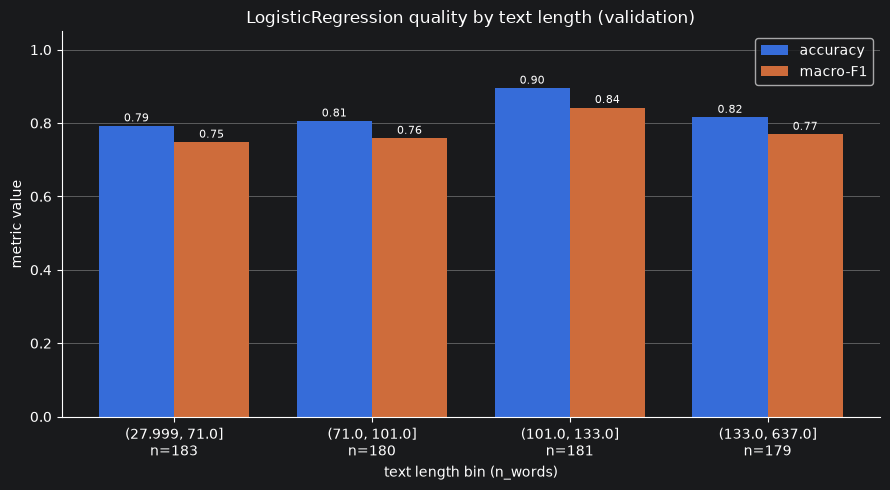

In [78]:
# TODO: wykres accuracy i macro-F1 vs koszyk (z podaniem n przy każdym słupku)


x = np.arange(len(length_df))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
bars_acc = ax.bar(x - width / 2, length_df["accuracy"], width, label="accuracy")
bars_f1 = ax.bar(x + width / 2, length_df["macro-F1"], width, label="macro-F1")

for bars in (bars_acc, bars_f1):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"{b}\nn={n}" for b, n in zip(length_df["bin"], length_df["n"])])
ax.set_xlabel("text length bin (n_words)")
ax.set_ylabel("metric value")
ax.set_ylim(0, 1.05)
ax.set_title("LogisticRegression quality by text length (validation)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="lightgray", linewidth=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Najsłabiej model radzi sobie z najkrótszymi tekstami (28–71 słów: macro-F1 0.748), a najlepiej ze średnio długimi (101–133 słów: 0.842). Najdłuższe teksty (133–637 słów) znów wypadają słabiej (0.769), możliwe, że przez częstsze mieszanie zalet i wad w jednej recenzji. Każdy koszyk ma ok. 180 przykładów, więc różnice rzędu 0.01–0.02 (np. między dwoma pierwszymi koszykami) to szum, ale różnica ok. 0.09 między najkrótszymi a średnio długimi tekstami jest wyraźna.


# Czego właściwie nauczył się model?

Dla modelu liniowego możemy obejrzeć cechy o największych wagach.

To nie jest pełne wyjaśnienie modelu, ale bardzo użyteczne narzędzie diagnostyczne.

Dla każdej klasy proszę wypisać:

- 15 cech o najwyższej dodatniej wadze,
- 15 o najniższej.

Tym samym proszę sprawdzić, czy model uczy się sensownych sygnałów, czy przypadkowych artefaktów.


In [79]:
# TODO: dla LogisticRegression: pipeline.named_steps["tfidf"].get_feature_names_out() oraz clf.coef_ (kształt: klasy × cechy). Po 15 cech o najwyższej i najniższej wadze na klasę

feature_names = log_reg_pipe["tfidf"].get_feature_names_out()
clf = log_reg_pipe["logreg"]

for cls, coefs in zip(clf.classes_, clf.coef_):
    order = np.argsort(coefs)
    top =  order[::-1][:15]
    bottom =  order[:15]

    table = pd.DataFrame({
        "top_feature": feature_names[top],
        "top_weight": coefs[top],
        "bottom_feature": feature_names[bottom],
        "bottom_weight": coefs[bottom]
    })
    print(f"\n=== class: {cls} ===")
    display(table)


=== class: amb ===


,top_feature,top_weight,bottom_feature,bottom_weight
0,ale,3.129312,polecam,-1.973528
1,ok,2.429045,nie polecam,-1.695712
2,niestety,2.186471,odradzam,-1.033750
3,pokoje,1.787673,dzięki,-0.919751
4,brak,1.667928,lekarzy,-0.801988
5,jednak,1.644908,sposób,-0.787814
6,minus,1.613002,proc,-0.782021
7,dobre,1.569295,nigdy,-0.772080
8,dość,1.568844,lat,-0.770888
9,śniadania,1.547102,jego,-0.767029



=== class: minus ===


,top_feature,top_weight,bottom_feature,bottom_weight
0,nie polecam,5.795784,zawsze,-1.983815
1,nie,5.274381,bardzo,-1.917058
2,odradzam,3.410501,jest,-1.568585
3,niestety,2.780289,czysty,-1.541511
4,po,2.360687,prof,-1.506594
5,brak,2.266585,czyste,-1.455463
6,nic,2.099950,dla,-1.435715
7,sie,1.947569,dzięki,-1.411414
8,brudne,1.908592,smaczne,-1.389897
9,nawet,1.800772,dobre,-1.385978



=== class: plus ===


,top_feature,top_weight,bottom_feature,bottom_weight
0,polecam,4.433386,niestety,-3.325774
1,bardzo,4.294252,nie,-3.260570
2,zawsze,2.181821,nie polecam,-2.973922
3,doktora,1.827366,brak,-2.414777
4,miła,1.682520,odradzam,-1.600887
5,czyste,1.680497,bo,-1.256565
6,lekarzy,1.671685,czy,-1.244971
7,jestem,1.643783,jednak,-1.231146
8,dzięki,1.617645,ok,-1.197190
9,dziękuję,1.606569,za,-1.190819



=== class: zero ===


,top_feature,top_weight,bottom_feature,bottom_weight
0,proc,3.014081,bardzo,-2.870017
1,prof,2.943579,nie,-2.800496
2,polsce,2.002503,polecam,-2.500078
3,czy,1.903405,mnie,-2.477983
4,pap,1.863578,doktor,-2.330570
5,będzie,1.799876,pani,-2.261220
6,są,1.758092,obsługa,-2.035289
7,hoteli,1.669571,mi,-1.990955
8,roku,1.653500,em,-1.932398
9,także,1.640377,pokoje,-1.866675



# Zadanie 9: Ewaluacja cech

Proszę znaleźć:

1. trzy cechy, które wyglądają sensownie,
2. trzy cechy, które mogą być skrótem / artefaktem (podpowiedź: proszę przejrzeć tokeny krótkie i funkcyjne oraz pozostałości po pre-tokenizacji tekstów, np. `em`, `śmy`; domyślny tokenizer odrzuca tokeny jednoznakowe, więc `m` w `miała m` zniknie, a `em` w `Był em` zostanie),
3. jedną cechę, której obecność Cię zaskoczyła.

Następnie proszę odpowiedzieć:

> Czy wysoka waga cechy oznacza związek przyczynowy?

**Odpowiedź**

| Klasa | Cechy sensowne | Skróty / artefakty | Zaskoczenie |
|---|---|---|---|
| `amb` | `ale`, `jednak`, `niestety` (spójniki kontrastu łączące zalety i wady) | `proc`, `dr`, `lat` | `śniadania`  |
| `minus` | `"nie polecam"`, `odradzam`, `niestety` | `proc`, `prof`, `sie`  | `lekarza`  |
| `plus` | `polecam`, `"bardzo dobre"`, `czyste` | `zł`  | `doktora` |
| `zero` | `polsce`, `roku`, `będzie` | `proc`, `prof`, `pap` `em`  | `pap`|

**Wniosek:** w klasach `plus` i `minus` model korzysta głównie ze słownictwa oceniającego. Klasa `zero` opiera się w dużej mierze na gatunku tekstu (prasa kontra recenzja), a `amb` częściowo na domenie (hotele kontra lekarze).

**Czy wysoka waga cechy oznacza związek przyczynowy?**

Nie. Waga mówi tylko, że w danych treningowych cecha **współwystępuje** z daną klasą, przy uwzględnieniu pozostałych cech. Nie mówi, że ją **powoduje**. Na przykład `pap` nie sprawia, że tekst jest neutralny. Po prostu neutralne teksty w PolEmo często pochodzą z prasy, a recenzje hoteli częściej są ambiwalentne. Same wagi też nie są wiarygodną miarą ważności: zależą od skalowania TF-IDF, regularyzacji i korelacji między cechami (np. `nie` i `"nie polecam"` dzielą się sygnałem). Wpływ cechy na decyzję można sprawdzić tylko interwencją, np. usuwając lub podmieniając token i obserwując zmianę predykcji. Taki test mówi jednak o działaniu modelu, a nie o przyczynowości w języku.


# Prawdopodobieństwo predykcji i selektywna klasyfikacja

`LogisticRegression` zwraca `predict_proba`.

Możemy zbudować prostą zasadę:

> jeśli maksymalne prawdopodobieństwo < próg, model nie odpowiada.

To nazywamy m.in. abstention, reject option albo selektywną klasyfikacją.

W prawdziwym wdrożonym systemie czasem lepiej powiedzieć:

> „nie wiem / skieruj do człowieka”

niż wymusić odpowiedź.


In [80]:
#TODO: predict_proba

def predict_with_threshold(model,X, threshold):
    probs = model.predict_proba(X)
    preds = model.predict(X)
    accepted = probs.max(axis=1) >= threshold
    return preds[accepted], accepted


# Zadanie 10: Pokrycie i jakość

Dla progów:

`0.40, 0.50, 0.60, 0.70, 0.80, 0.90`

proszę policzyć:

- `coverage`: na jakiej części danych model udziela odpowiedzi,
- accuracy na zaakceptowanych przykładach,
- macro-F1 na zaakceptowanych przykładach.

Uwaga: przy wysokich progach niektóre klasy mogą nie wystąpić wśród zaakceptowanych przykładów. Proszę liczyć `f1_score(..., labels=CLASSES, average="macro", zero_division=0)` i raportować `n` zaakceptowanych. Prawdopodobieństwa dostępne są tylko dla LogisticRegression (LinearSVC nie ma `predict_proba`).

Proszę narysować:

`coverage` vs `accuracy`

### Pytanie

Czy da się zwiększyć jakość systemu bez zmiany modelu? Jeśli tak, to jak?

In [81]:
# TODO: coverage vs accuracy

thresholds = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
CLASSES = list(log_reg_pipe.classes_)
rows = []

for t in thresholds:
    y_pred_acc, accepted = predict_with_threshold(log_reg_pipe, X_val, t)
    y_true_acc =  y_val.values[accepted]
    n = int(accepted.sum())
    rows.append({
        "threshold": t,
        "n": n,
        "coverage": accepted.mean(),
        "accuracy": accuracy_score(y_true_acc, y_pred_acc) if n else np.nan,
        "f1_score": f1_score(y_true_acc, y_pred_acc, labels=CLASSES, average="macro", zero_division=0) if n else np.nan
    })

selective_df = pd.DataFrame(rows)
selective_df

,threshold,n,coverage,accuracy,f1_score
0,0.4,667,0.922545,0.856072,0.808696
1,0.5,522,0.721992,0.929119,0.843736
2,0.6,405,0.560166,0.950617,0.806521
3,0.7,274,0.378976,0.974453,0.740485
4,0.8,140,0.193638,1.000000,0.750000
5,0.9,23,0.031812,1.000000,0.750000


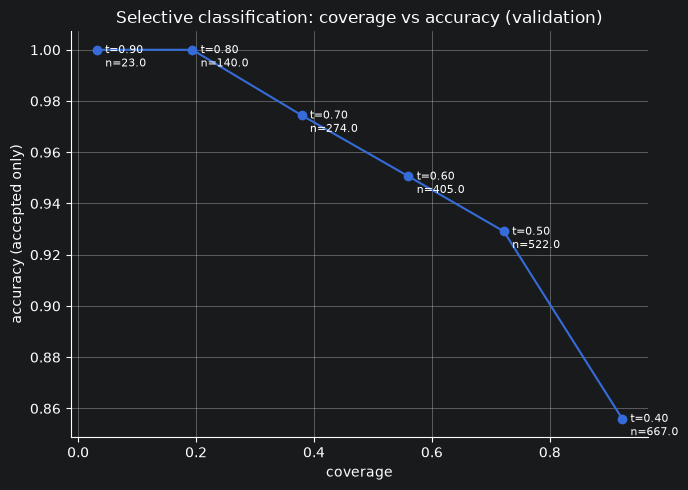

In [82]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(selective_df["coverage"], selective_df["accuracy"], marker="o")

for _, r in selective_df.iterrows():
    ax.annotate(f"t={r.threshold:.2f}\nn={r.n}", (r.coverage, r.accuracy),
                textcoords="offset points", xytext=(6, -12), fontsize=8)

ax.set_xlabel("coverage")
ax.set_ylabel("accuracy (accepted only)")
ax.set_title("Selective classification: coverage vs accuracy (validation)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="lightgray", linewidth=0.5)
plt.tight_layout()
plt.show()

Tak, zmieniając regułę decyzji, a nie model:
 - **Selektywna klasyfikacja**: odrzucanie przykładów z niską pewnością i kierowanie ich do człowieka. Jakość na zaakceptowanych rośnie kosztem pokrycia. Próg dobieramy na walidacji pod wymagane pokrycie lub dokładność.
 - **Progi lub wagi per klasa** zamiast argmax, np. niższy próg dla `amb`, którą model rzadko wybiera. To może poprawić macro-F1.

 - **Kalibracja prawdopodobieństw (CalibratedClassifierCV)** sprawia, że próg 0.8 faktycznie znaczy „~80% trafności”, bez zmiany samego klasyfikatora.

In [83]:
# TODO: improvement_experiment
from itertools import product

proba_val = log_reg_pipe.predict_proba(X_val)
classes = log_reg_pipe.classes_
y_val_arr = y_val.values

def decide(proba, weights):
    return classes[(proba * weights).argmax(axis=1)]

def val_macro_f1(weights):
    return f1_score(y_val_arr, decide(proba_val, weights), labels=CLASSES, average='macro', zero_division=0)

base_w = np.ones(len(classes))

priors = train_df["target"].value_counts(normalize=True).reindex(classes).values
prior_w = 1 / priors

grid = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
tuned_w = max((np.array(w) for w in product(grid, repeat=len(classes))), key=val_macro_f1)

rows = []
for name, w in {"argmax (baseline)": base_w, "prior correction": prior_w, "tuned class weights": tuned_w}.items():
    y_pred = decide(proba_val, w)
    rows.append({
        "rule": name,
        "weights": dict(zip(classes, np.round(w, 2))),
        "accuracy": accuracy_score(y_val_arr, y_pred),
        "macro-F1": f1_score(y_val_arr, y_pred, labels=CLASSES, average="macro", zero_division=0),
        **{f"F1_{c}": f for c, f in zip(CLASSES, f1_score(y_val_arr, y_pred, labels=CLASSES, average=None, zero_division=0))},
    })

improvement_df = pd.DataFrame(rows).round(3)
improvement_df

,rule,weights,accuracy,macro-F1,F1_amb,F1_minus,F1_plus,F1_zero
0,argmax (baseline),"{'amb': 1.0, 'minus': 1.0, 'plus': 1.0, 'zero': 1.0}",0.827,0.793,0.479,0.855,0.856,0.980
1,prior correction,"{'amb': 5.51, 'minus': 2.64, 'plus': 3.69, 'zero': 5.95}",0.801,0.788,0.523,0.846,0.814,0.969
2,tuned class weights,"{'amb': 0.75, 'minus': 0.5, 'plus': 0.75, 'zero': 0.75}",0.837,0.813,0.535,0.870,0.855,0.992


Ten sam wytrenowany model, inna reguła decyzji: wagi per klasa dobrane na walidacji podnoszą macro-F1 z 0.793 do 0.813, a accuracy z 0.827 do 0.837. Dobrane wagi w praktyce osłabiają klasę `minus` względem pozostałych, w którą model najczęściej wpychał opinie ambiwalentne, więc najwięcej zyskuje `amb` (F1 0.479 → 0.535). Korekta priorów (1/częstość) daje 0.788, czyli gorzej niż argmax: zbyt mocno faworyzuje rzadkie klasy, przez co traci `plus` (0.856 → 0.814). Wagi dobrano na tym samym zbiorze, na którym je oceniamy, więc 0.813 to wynik optymistyczny.


# Tuning hiperparametrów

Sprawdzimy jeden parametr Logistic Regression:

`C ∈ {0.1, 0.5, 1, 2, 5}`

Obliczeń dokonujemy na splicie walidacyjnym. To wystarczy, by przećwiczyć prawidłowy protokół:

`train → validation → wybór → test`


## Zadanie 11: Strojenie hiperparametru C

Proszę przeprowadzić strojenie hiperparametru C dla modelu regresji logistycznej.
- przetestować wartości C: 0.1, 0.5, 1.0, 2.0 i 5.0.
- dla każdej wartości wytrenować osobny model LogisticRegression na reprezentacji TF-IDF zbioru treningowego.
- wykonać predykcję dla zbioru walidacyjnego.
- obliczyć metryki jakości modelu, w szczególności macro F1.
- zapisać wyniki dla wszystkich wartości C w tabeli.
- posortować wyniki malejąco według macro F1.
- wybrać wartość C, dla której model uzyskał najlepszy wynik na zbiorze walidacyjnym.
Jeśli najlepsze C leży na brzegu siatki (5.0), proszę poszerzyć siatkę i powtórzyć.

Na końcu krótko odpowiedzieć: jak zmiana wartości C wpłynęła na jakość klasyfikacji i która wartość została wybrana?

In [84]:
# TODO: strojenie C na validation (nie na test!)


c_values =  [0.1, 0.5, 1, 2, 5, 5.5 , 6, 10]
rows = []
for c in c_values:
    pipe = Pipeline(
        steps=[
            ("tfidf", clone(word_tfidf) ),
            ("clf", LogisticRegression(max_iter=1000,C=c,random_state=RANDOM_STATE))
        ]
    )
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_val)

    rows.append({
        "C":c,
        "accuracy": accuracy_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred, average="macro"),
        "macro_f1": macro_f1(y_val, y_pred)
    })

tuned_df = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
tuned_df

,C,accuracy,recall,macro_f1
0,5.5,0.827109,0.795136,0.800127
1,5.0,0.824343,0.790738,0.796510
2,6.0,0.821577,0.788707,0.793433
3,1.0,0.827109,0.784090,0.792552
4,2.0,0.822960,0.785433,0.791903
5,10.0,0.818811,0.785816,0.790786
6,0.5,0.817427,0.759516,0.765631
7,0.1,0.683264,0.584712,0.570517


Zbyt małe C pogarsza wyniki (C=0.1: macro-F1 0.571). Najlepsze C z pierwotnej siatki (5.0) leżało na jej brzegu, dlatego rozszerzyliśmy siatkę o wartości 5.5, 6 i 10. Dla C od 1 do 10 jakość jest niemal stała (0.791–0.800), a najlepsza okazała się wartość C=5.5 (macro-F1 0.800, accuracy 0.827), która leży już wewnątrz siatki.


# Zadanie 12: Finalista

Na podstawie splitu proszę wybrać jeden finalny pipeline.

Nie musi to być model z absolutnie najwyższym wynikiem, jeśli różnica jest minimalna, a koszt znacząco większy.

Proszę uzasadnić:

> **Wybrany model:** `TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)` + `LogisticRegression(C=5.5, max_iter=1000, random_state=42)`

> **Dlaczego:** To najlepsza konfiguracja regresji logistycznej na pełnym zbiorze walidacyjnym (macro-F1 0.800, accuracy 0.827). Model ma interpretowalne cechy (słowa i bigramy, co wykorzystaliśmy w analizie wag) i zwraca `predict_proba`, więc umożliwia selektywną klasyfikację: przy progu 0.5 macro-F1 na zaakceptowanych przykładach rośnie do 0.84 kosztem pokrycia.

> **Najważniejszy trade-off:** Rezygnujemy z najlepszego wyniku w labie, który uzyskał `TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 5), min_df=2, max_features=50_000, sublinear_tf=True)` + `LinearSVC(random_state=42)` (macro-F1 0.810). Różnica 0.01 mieści się w przedziale ufności z bootstrapu, więc można ją uznać za szum. W zamian dostajemy model ok. 4× tańszy w treningu (reprezentacja word: 1.5 s vs char_wb: 6.0 s w ablacji), łatwiejszy do interpretacji i z możliwością odrzucania niepewnych predykcji, której LinearSVC nie daje.



# Zadanie 13: Ostateczny test modelu

Kiedy mamy już wszystkie niezbędne informacje, wolno nam użyć test setu do finalnej oceny.

Proszę wybrać konfigurację na podstawie validation i:

1. połącz `train + validation`,
2. wytrenuj model od nowa,
3. oceń dokładnie raz na `test`.

Proszę nie poprawiać konfiguracji po zobaczeniu testu ;)


In [85]:
#TODO: TEST

X_train_final = pd.concat([X_train, X_val], ignore_index=True)
y_train_final = pd.concat([y_train, y_val], ignore_index=True)

final_pipe = Pipeline(
    steps=[
        ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)),
        ("logreg", LogisticRegression(C=5.5, max_iter=1000, random_state=42))
    ]
)

ts = time.perf_counter()
final_pipe.fit(X_train_final, y_train_final)
te = time.perf_counter()
y_final_pred = final_pipe.predict(X_test)
final_train_s = te - ts



In [86]:
f1, ci_low, ci_high = bootstrap_ci(y_test, y_final_pred, metric=macro_f1)

print(f"accuracy:     {accuracy_score(y_test, y_final_pred):.6f}")
print(f"macro-recall: {recall_score(y_test, y_final_pred, average='macro'):.6f}")
print(f"macro-F1:     {f1:.6f} (95% CI: {ci_low:.6f}–{ci_high:.6f})")
print(f"train time:   {final_train_s:.2f} s")


accuracy:     0.832410
macro-recall: 0.788515
macro-F1:     0.800116 (95% CI: 0.766481–0.831343)
train time:   3.02 s


In [87]:
print(classification_report(y_test, y_final_pred, digits=6))

              precision    recall  f1-score   support

         amb   0.600000  0.444444  0.510638       108
       minus   0.814706  0.923333  0.865625       300
        plus   0.863874  0.837563  0.850515       197
        zero   1.000000  0.948718  0.973684       117

    accuracy                       0.832410       722
   macro avg   0.819645  0.788515  0.800116       722
weighted avg   0.826032  0.832410  0.825913       722




# NLP Arena #1

Teraz model musi zostać oceniony jak system, a nie tylko liczba F1.

Dla finalistów raportujemy:

### Quality
- macro-F1,
- accuracy.

### Speed
- czas treningu,
- inference ms / dokument.

### Size
- rozmiar zapisanego pipeline'u.

### Robustness
- wynik na krótkich tekstach,
- wynik na długich tekstach.

### Interpretability
- czy możemy obejrzeć ważne cechy?

## Kategorie

**Best Quality**: najwyższe macro-F1  
**Speed Demon**: najniższe inference time  
**Tiny but Mighty**: najlepszy stosunek jakości do rozmiaru  
**Occam Award**: najprostszy system blisko najlepszego wyniku  
**Failure Analyst**: najlepsza analiza błędów


Proszę zapisać wytrenowany model do pliku i zmierzyć podstawowe parametry związane z jego wykorzystaniem.
- zapisać końcowy model do pliku w formacie joblib.
- obliczyć rozmiar zapisanego modelu w MB.
- wyświetlić czas treningu modelu w sekundach.
- obliczyć średni czas inferencji dla jednego dokumentu i podać go w milisekundach na dokument (ms/doc).
- zapisać otrzymane wartości i wykorzystać je później do porównania z innymi modelami.

Porównując modele, proszę zwrócić uwagę nie tylko na jakość klasyfikacji, ale również na ich rozmiar oraz koszt treningu i inferencji.

In [88]:
MODEL_PATH = ARTIFACTS / "final_pipe.joblib"
joblib.dump(final_pipe, MODEL_PATH)
model_size_mb = MODEL_PATH.stat().st_size / 1024**2


times = []

for _ in range(3):
    t_s = time.perf_counter()
    final_pipe.predict(X_test)
    t_e = time.perf_counter()
    times.append(t_e - t_s)

final_ms_per_doc =  np.median(times)  / len(X_test)* 1000

final_metrics = {
    "size_mb": model_size_mb,
    "train_s": final_train_s,
    "infer_ms/doc": final_ms_per_doc,
}

print(f"saved to:     {MODEL_PATH}")
print(f"size:         {model_size_mb:.2f} MB")
print(f"train time:   {final_train_s:.2f} s")
print(f"inference:    {final_ms_per_doc:.4f} ms/doc")

saved to:     ../artifacts/final_pipe.joblib
size:         3.46 MB
train time:   3.02 s
inference:    0.0774 ms/doc


In [89]:
import io

def size_mb(model):
    buf = io.BytesIO()
    joblib.dump(model, buf)
    return buf.getbuffer().nbytes / 1024**2

finalists = {
    "LogReg word (1, 2), C=5.5": (
        Pipeline([("tfidf", clone(word_tfidf)),
                  ("clf", LogisticRegression(C=5.5, max_iter=1000, random_state=RANDOM_STATE))]),
        "tak (słowa i bigramy)",
    ),
    "LinearSVC char_wb (1, 5)": (
        Pipeline([("tfidf", clone(variants["char_wb (1, 5)"])),
                  ("clf", LinearSVC(random_state=RANDOM_STATE))]),
        "częściowo (fragmenty słów)",
    ),
    "Dummy stratified": (
        DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
        "nie",
    ),
}

short_mask = (val_df["n_words"] <= val_df["n_words"].quantile(0.25)).values
long_mask = (val_df["n_words"] >= val_df["n_words"].quantile(0.75)).values
y_val_arr = y_val.values

rows = []
for name, (model, interpretability) in finalists.items():
    t_s = time.perf_counter()
    model.fit(X_train, y_train)
    train_s = time.perf_counter() - t_s

    y_pred = model.predict(X_val)

    times = []
    for _ in range(3):
        t_1 = time.perf_counter()
        model.predict(X_val)
        times.append(time.perf_counter() - t_1)

    mb = size_mb(model)
    f1 = macro_f1(y_val_arr, y_pred)
    rows.append({
        "model": name,
        "macro-F1": f1,
        "accuracy": accuracy_score(y_val_arr, y_pred),
        "train_s": train_s,
        "infer_ms/doc": np.median(times) / len(X_val) * 1000,
        "size_mb": mb,
        "F1_per_MB": f1 / mb,
        "macro-F1 short (Q1)": macro_f1(y_val_arr[short_mask], y_pred[short_mask]),
        "macro-F1 long (Q4)": macro_f1(y_val_arr[long_mask], y_pred[long_mask]),
        "interpretability": interpretability,
    })

arena_df = pd.DataFrame(rows).round(4).sort_values("macro-F1", ascending=False)
arena_df

,model,macro-F1,accuracy,train_s,infer_ms/doc,size_mb,F1_per_MB,macro-F1 short (Q1),macro-F1 long (Q4),interpretability
1,"LinearSVC char_wb (1, 5)",0.8104,0.8409,6.0754,0.8713,3.1798,0.2549,0.8009,0.7976,częściowo (fragmenty słów)
0,"LogReg word (1, 2), C=5.5",0.8001,0.8271,2.5539,0.0760,3.4644,0.2310,0.7346,0.7664,tak (słowa i bigramy)
2,Dummy stratified,0.2310,0.2683,0.0018,0.0003,0.0007,325.9649,0.1958,0.2028,nie


**Wyniki areny**

Porównanie finalistów przeprowadzono na zbiorze walidacyjnym (modele trenowane na train), aby nie używać zbioru testowego ponownie. Wynik na teście raportujemy tylko dla finalnego modelu (Zadanie 13).

**Best Quality:** LinearSVC char_wb (1, 5): macro-F1 0.810, accuracy 0.841.

**Speed Demon:** LogReg word (1, 2), C=5.5: 0.08 ms/doc, ok. 11× szybciej niż LinearSVC char_wb (0.87 ms/doc). Char n-gramów na dokument jest dużo więcej niż słów. Dummy jest szybszy, ale nie jest realnym systemem.

**Tiny but Mighty:** LinearSVC char_wb (1, 5): 0.255 macro-F1/MB vs 0.231 dla LogReg word. Oba modele mają ok. 3 MB (limit 50k cech), więc char_wb wygrywa wyższym F1 przy nieco mniejszym rozmiarze (3.18 vs 3.46 MB).

**Occam Award:** LogReg word (1, 2), C=5.5: najprostszy system blisko najlepszego wyniku (−0.010 macro-F1, w granicach przedziału ufności). Trenuje się ponad 2× szybciej (2.6 s vs 6.1 s) i ma interpretowalne cechy.

**Failure Analyst:** LogReg word (1, 2), C=5.5: dla tego modelu przeprowadziliśmy galerię błędów, analizę jakości względem długości tekstu i analizę wag cech.

**Robustness:** char_wb jest wyraźnie lepszy na krótkich tekstach (macro-F1 0.801 vs 0.735) i nieco lepszy na długich (0.798 vs 0.766). W krótkim tekście jest mało słów, więc model słowny ma mało sygnału, a n-gramy znakowe wyciągają informację także z fragmentów słów, odmian i literówek. To najmocniejszy argument za char_wb.

**Podsumowanie:** LinearSVC char_wb wygrywa jakością, rozmiarem i odpornością na krótkie teksty. LogReg word wygrywa szybkością inferencji, prostotą, interpretowalnością i tym, że zwraca `predict_proba` (selektywna klasyfikacja). Wybór finalisty zależy więc od zastosowania. Przy przewadze 0.01 macro-F1 zostajemy przy LogReg word, ale jeśli system ma obsługiwać głównie krótkie opinie, lepszym wyborem byłby char_wb.

# Zadanie 14: Baseline Boss Fight

Zadanie związane z areną, skupiamy się w nim na następujących aspektach:

### A. Word + char features
Proszę połączyć reprezentację słowną i znakową przez `FeatureUnion`.

### B. Class weights
Sprawdzić `class_weight="balanced"`. Czy macro-F1 rośnie? Które klasy zyskują, a które tracą?

### C. Learning curve
Proszę wytrenować ten sam model na:

- 10% train,
- 25%,
- 50%,
- 75%,
- 100%.

Proszę powtórzyć dla 3 różnych seedów losowania podzbiorów i raportować średnią ± odchylenie.

Proszę narysować:

`liczba przykładów → macro-F1`

Proszę odpowiedzieć: Czy bardziej opłaca się zmienić model, czy zdobyć więcej danych?

### D. Robustness test
Proszę zastosować zaburzenia do całego zbioru validation (n=723; 100 przykładów daje zbyt szeroki przedział ufności). Proszę wprowadzić kontrolowany szum:

- usunąć polskie znaki,
- dodać literówki,
- zmienić wielkość liter.

Proszę sprawdzić spadek wyniku word-TF-IDF i char-TF-IDF.

### E. Cost-aware model selection
Proszę zdefiniować własny score:

```text
utility = macro_f1 - λ * log10(model_size_mb + 1)
```
Proszę sprawdzić λ ∈ {0.01, 0.05, 0.1} i sprawdzić, czy najlepszy model nadal wygrywa.

In [90]:
classifiers = {
    "default": LogisticRegression(C=5.5, max_iter=1000, random_state=RANDOM_STATE),
    "balanced": LogisticRegression(C=5.5, max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
}

combine_representation = FeatureUnion(transformer_list=[
    ("word", clone(word_tfidf)),
    ("char", clone(variants["char_wb (1, 5)"])),
])

rows, per_class = [], {}
boss_models = {}

for clf_name, clf_model in classifiers.items():
    combine_pipe = Pipeline(steps=[
        ("tfidf", clone(combine_representation)),
        ("clf", clone(clf_model)),
    ])

    t_s = time.perf_counter()
    combine_pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - t_s

    y_pred = combine_pipe.predict(X_val)
    boss_models[f"union word+char, {clf_name}"] = combine_pipe

    rows.append({
        "model": f"union word+char, {clf_name}",
        "macro-F1": macro_f1(y_val, y_pred),
        "accuracy": accuracy_score(y_val, y_pred),
        "train_s": train_time,
        "size_mb": size_mb(combine_pipe),
    })
    per_class[clf_name] = f1_score(y_val, y_pred, labels=CLASSES, average=None)

union_df = pd.DataFrame(rows).round(4)

class_weight_df = pd.DataFrame(per_class, index=CLASSES)
class_weight_df["diff (balanced - default)"] = class_weight_df["balanced"] - class_weight_df["default"]
class_weight_df = class_weight_df.round(4)

display(union_df, class_weight_df)

,model,macro-F1,accuracy,train_s,size_mb
0,"union word+char, default",0.8037,0.8313,11.3958,6.6429
1,"union word+char, balanced",0.8155,0.8326,13.1587,6.6429


,default,balanced,diff (balanced - default)
amb,0.5045,0.5565,0.0519
minus,0.8834,0.8901,0.0067
plus,0.8387,0.8232,-0.0155
zero,0.9882,0.9922,0.0040


**A. Czy połączenie reprezentacji pomaga?**

Union word + char_wb z LogReg (C=5.5) daje macro-F1 0.804. To tylko +0.004 względem samego word (0.800 w arenie) i mniej niż LinearSVC na samym char_wb (0.810). Kosztem jest 2× większy model (6.6 vs 3.5 MB) i kilkukrotnie dłuższy trening (ok. 11 s vs 2.6 s). Sama unia się nie opłaca, a wyraźny zysk daje dopiero `class_weight="balanced"` (0.816).

**B. Czy class_weight="balanced" pomaga?**

Tak, macro-F1 rośnie z 0.804 do 0.816 (+0.012), a accuracy praktycznie się nie zmienia (0.831 → 0.833). Najwięcej zyskuje rzadka klasa amb (F1 0.505 → 0.557, +0.052): wagi zmuszają model, by częściej ją przewidywał. Lekko zyskują też minus (+0.007) i zero (+0.004). Traci tylko plus (0.839 → 0.823, −0.016), bo część jego przykładów trafia teraz do amb. Ważenie klas przesuwa więc jakość z klasy częstej na rzadką, co poprawia macro-F1.

In [91]:
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
seeds = [40, 41, 42]
rows = []

for frac in fractions:
    for seed in seeds:
        X_train_split = X_train.sample(frac=frac, random_state=seed)
        y_train_split = y_train[X_train_split.index]
        pipe = Pipeline(
            steps=[
                ("tfidf", clone(word_tfidf)),
                ("clf", clone(classifiers["default"])),
            ]
        )
        pipe.fit(X_train_split, y_train_split)
        y_pred = pipe.predict(X_val)

        rows.append({
            "fraction": frac,
            "seed": seed,
            "n_train": len(X_train_split),
            "macro_f1": macro_f1(y_val, y_pred),
        })

lc_df = (
    pd.DataFrame(rows)
    .groupby("fraction")
    .agg(
        n_train=("n_train", "first"),
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
    )
    .reset_index()
)
lc_df

,fraction,n_train,mean_macro_f1,std_macro_f1
0,0.10,578,0.706506,0.022788
1,0.25,1446,0.762686,0.011180
2,0.50,2891,0.790917,0.003579
3,0.75,4336,0.786342,0.006759
4,1.00,5782,0.800127,0.000000


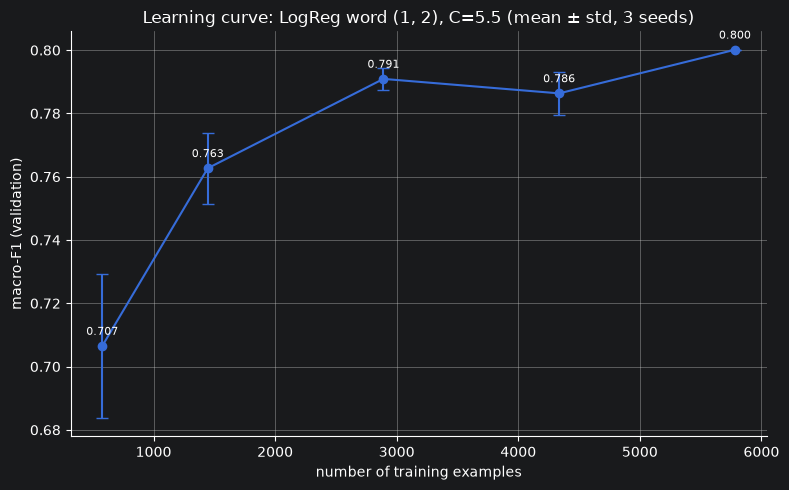

In [92]:

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(lc_df["n_train"], lc_df["mean_macro_f1"], yerr=lc_df["std_macro_f1"],
            marker="o", capsize=4)

for _, r in lc_df.iterrows():
    ax.annotate(f"{r.mean_macro_f1:.3f}", (r.n_train, r.mean_macro_f1),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax.set_xlabel("number of training examples")
ax.set_ylabel("macro-F1 (validation)")
ax.set_title("Learning curve: LogReg word (1, 2), C=5.5 (mean ± std, 3 seeds)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="lightgray", linewidth=0.5)
plt.tight_layout()
plt.show()

Zmienić model czy zdobyć więcej danych?

Krzywa uczenia szybko się wypłaszcza: od 10% do 50% danych macro-F1 rośnie z 0.707 do 0.791, ale od 50% do 100% już tylko o ok. 0.009 (spadek przy 75% mieści się w odchyleniu między seedami). Dwukrotne zwiększenie zbioru dało więc mniej niż zmiana modelu przy tych samych danych: union word+char z class_weight="balanced" osiąga 0.816 (+0.015 względem finalisty), a LinearSVC char_wb 0.810 (+0.010). Na tym etapie bardziej opłaca się zmienić model lub reprezentację niż zbierać więcej danych. Wszystkie te różnice są jednak mniejsze niż przedział ufności (~±0.03), więc to trend, a nie pewny wynik.

In [93]:
PL_MAP = str.maketrans("ąćęłńóśźżĄĆĘŁŃÓŚŹŻ", "acelnoszzACELNOSZZ")

def strip_diacritics(text):
    return text.translate(PL_MAP)

def make_final_lr(vectorizer=word_tfidf):
    return Pipeline([ ("tfidf", clone(vectorizer)), ("clf", LogisticRegression(C=5.5, max_iter=1000, random_state=RANDOM_STATE)), ])

def add_typos(text, rng, p=0.1):
    words = text.split()
    for i, w in enumerate(words):
        if len(w) > 3 and rng.random() < p:
            j = rng.integers(0, len(w) - 1)
            words[i] = w[:j] + w[j + 1] + w[j] + w[j + 2:]
    return " ".join(words)

rng = np.random.default_rng(RANDOM_STATE)
perturbations = {
    "clean": X_val,
    "no diacritics": X_val.map(strip_diacritics),
    "typos (10% words)": X_val.map(lambda t: add_typos(t, rng)),
    "UPPERCASE": X_val.str.upper(),
}

robust_models = {
    "word-TF-IDF": make_final_lr(word_tfidf).fit(X_train, y_train),
    "char-TF-IDF": make_final_lr(variants["char_wb (1, 5)"]).fit(X_train, y_train),
}

rows = []
for model_name, model in robust_models.items():
    for pert_name, X_pert in perturbations.items():
        rows.append({
            "model": model_name,
            "perturbation": pert_name,
            "macro_f1": macro_f1(y_val, model.predict(X_pert)),
        })

robust_df = pd.DataFrame(rows).pivot(index="perturbation", columns="model", values="macro_f1")
robust_df = robust_df.loc[list(perturbations)]
display(robust_df.round(6))

model,char-TF-IDF,word-TF-IDF
perturbation,,
clean,0.807974,0.800127
no diacritics,0.771936,0.727115
typos (10% words),0.805745,0.789113
UPPERCASE,0.807974,0.800127


**D. Odporność na zaburzenia** (macro-F1 na całym zbiorze walidacyjnym; w nawiasie spadek względem czystych danych)

| zaburzenie | word-TF-IDF | char-TF-IDF |
|---|---:|---:|
| czyste | 0.800 | 0.808 |
| bez polskich znaków | 0.727 (−0.073) | 0.772 (−0.036) |
| literówki (10% słów) | 0.789 (−0.011) | 0.806 (−0.002) |
| WIELKIE LITERY | 0.800 (0.000) | 0.808 (0.000) |

Usunięcie polskich znaków szkodzi najbardziej. Zmiana wielkości liter nie zmienia wyniku żadnego modelu, bo `TfidfVectorizer` domyślnie zamienia litery na małe (`lowercase=True`). Char-TF-IDF jest ok. 2× odporniejszy na brak polskich znaków i prawie niewrażliwy na literówki, bo zaburzone słowo nadal dzieli wiele n-gramów znakowych z oryginałem. Dla modelu słownego „zle” to zupełnie nowe słowo, nieobecne w słowniku.

In [94]:
candidates = pd.concat([
    arena_df[["model", "macro-F1", "size_mb"]],
    union_df[["model", "macro-F1", "size_mb"]],
], ignore_index=True)

lambdas = [0.01, 0.05, 0.1]
for lam in lambdas:
    candidates[f"utility λ={lam}"] = candidates["macro-F1"] - lam * np.log10(candidates["size_mb"] + 1)

utility_df = candidates.sort_values("macro-F1", ascending=False).reset_index(drop=True).round(6)
display(utility_df)

for lam in lambdas:
    col = f"utility λ={lam}"
    print(f"λ={lam}: winner = {utility_df.loc[utility_df[col].idxmax(), 'model']}")


,model,macro-F1,size_mb,utility λ=0.01,utility λ=0.05,utility λ=0.1
0,"union word+char, balanced",0.8155,6.6429,0.806667,0.771337,0.727174
1,"LinearSVC char_wb (1, 5)",0.8104,3.1798,0.804188,0.779342,0.748284
2,"union word+char, default",0.8037,6.6429,0.794867,0.759537,0.715374
3,"LogReg word (1, 2), C=5.5",0.8001,3.4644,0.793602,0.767612,0.735124
4,Dummy stratified,0.2310,0.0007,0.230997,0.230985,0.230970


λ=0.01: winner = union word+char, balanced
λ=0.05: winner = LinearSVC char_wb (1, 5)
λ=0.1: winner = LinearSVC char_wb (1, 5)


Przy λ=0.01 kara za rozmiar jest pomijalna i wygrywa najlepszy jakościowo model (union word+char, balanced). Już przy λ=0.05 traci prowadzenie na rzecz LinearSVC char_wb. Jest ok. 2× mniejszy (3.2 vs 6.6 MB), a ustępuje tylko o 0.005 macro-F1. Przy λ=0.1 przewaga mniejszych modeli rośnie. Najlepszy model wygrywa więc tylko wtedy, gdy koszt rozmiaru jest prawie nieistotny. Union łączy dwie reprezentacje (2 × 50k cech), więc podwaja rozmiar za niewielki zysk jakości.


# Zadanie 15: Karta modelu

Proszę utworzyć:

```text
artifacts/baseline_model_card.md
```

Minimalna zawartość:
- Jaki pipeline?
- Co przewiduje?
- Na czym został wytrenowany?
- Jakie splity i jaka główna metryka?
- Validation i final test.
- Czas treningu i inference.
- Co wynika z zaobserwowanych porażek?
- Czy próg confidence ma sens?
- Do czego model może być użyty? Do czego nie powinien być używany?



# Raport końcowy

Proszę podsumować pracę i określić:

1. **Najlepszy model:** ...
2. **Poprawa względem majority baseline:** ...
3. **Najtrudniejsza klasa:** ...
4. **Najważniejszy typ błędu:** ...
5. **Najważniejszy trade-off jakość/koszt:** ...
6. **Czy na tym etapie potrzebujemy większego modelu?** ...

Każde sformułowanie proszę uzasadnić.

1. **Najlepszy model:** TF-IDF word (1, 2) + LogisticRegression (C=5.5). Na teście osiąga macro-F1 0.800 (95% CI: 0.766–0.831) i accuracy 0.832, czyli tyle samo co na walidacji (0.800). Wyższe wyniki walidacyjne miały LinearSVC na `char_wb` (0.810) i union word+char z `class_weight="balanced"` (0.816), ale różnice mieszczą się w przedziałach ufności, a modele te są droższe i mniej interpretowalne.

2. **Poprawa względem majority baseline:** na walidacji macro-F1 wzrosło z 0.136 (`most_frequent`) i 0.231 (`stratified`) do 0.800, czyli o ok. 0.57–0.66, a accuracy z 0.375 do 0.827. Przedziały ufności w ogóle na siebie nie zachodzą, więc to realny postęp, a nie efekt losowości.

3. **Najtrudniejsza klasa:** `amb`, z F1 0.51 na teście (precision 0.60, recall 0.44). Pozostałe klasy mają F1 0.85–0.97. Teksty ambiwalentne zawierają jednocześnie pochwały i krytykę, a granica między `amb` i `minus` bywa subiektywna nawet dla anotatorów.

4. **Najważniejszy typ błędu:** `MIXED_SENTIMENT`, czyli 9 z 15 przykładów w galerii błędów, prawie zawsze z etykietą `amb`. Model wybiera dominującą polaryzację, najczęściej `minus` (50 przypadków `amb` → `minus` w macierzy pomyłek). Reprezentacja bag-of-words nie modeluje kontrastu („miła, ale…”), więc nie widzi, że tekst łączy obie strony.

5. **Najważniejszy trade-off jakość/koszt:** lepsze modele dają tylko +0.010–0.016 macro-F1, w granicach przedziału ufności. Kosztuje to ok. 11× wolniejszą inferencję (char_wb) albo 2× większy model i kilkukrotnie dłuższy trening (union). Przy karze za rozmiar (λ ≥ 0.05) najlepszy jakościowo model przestaje wygrywać. Wybrano prostszy model: szybki, interpretowalny i z `predict_proba`, co pozwala odrzucać niepewne predykcje (przy progu 0.5 accuracy 0.93 przy pokryciu 72%).

6. **Czy na tym etapie potrzebujemy większego modelu?** Krzywa uczenia się wypłaszcza, a zmiany w obrębie TF-IDF dają zyski rzędu szumu, więc tani baseline jest blisko swojego limitu (macro-F1 ok. 0.80). Pozostałe błędy (teksty mieszane, negacja w kontekście, ironia, krótkie teksty) wymagają rozumienia kontekstu, z którym modele kontekstowe (np. transformery) mogą radzić sobie lepiej. Większy model ma sens tylko wtedy, gdy na tym samym teście wyraźnie pokona 0.800, czyli wyjdzie ponad górną granicę przedziału ufności (ok. 0.83), zwłaszcza w klasie `amb`. W przeciwnym razie lepiej zostać przy baseline'ie z progiem confidence i weryfikacją człowieka.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli zawiera:

- [ ] majority baseline (oba warianty `DummyClassifier`);
- [ ] TF-IDF i opis macierzy rzadkiej;
- [ ] Logistic Regression;
- [ ] Linear SVM;
- [ ] leaderboard na validation z przedziałami ufności;
- [ ] classification report;
- [ ] confusion matrix;
- [ ] ablację word vs char n-grams;
- [ ] Failure Gallery z ręczną taksonomią błędów;
- [ ] analizę jakości względem długości tekstu;
- [ ] porównanie wag modelu liniowego;
- [ ] coverage vs quality;
- [ ] strojenie C (tabela, wybór na validation);
- [ ] wybór finalisty bez używania test setu;
- [ ] ostateczny test: train + validation, dokładnie jeden raz na test;
- [ ] zapisany model `.joblib` i pomiary (rozmiar, czas treningu, ms/doc);
- [ ] NLP Arena #1;
- [ ] Baseline Boss Fight;
- [ ] `baseline_model_card.md`;
- [ ] wnioski końcowe.